In [1]:
from tensorflow import keras
from sklearn.model_selection import train_test_split

In [2]:
(train_input, train_target), (test_input, test_target) = \
    keras.datasets.fashion_mnist.load_data()

In [3]:
print(train_input.shape)
print(test_input.shape)

(60000, 28, 28)
(10000, 28, 28)


In [4]:
train_scaled = train_input.reshape(-1, 28, 28, 1) / 255.0  # 4차원 (데이터개수, 행, 열, 채널)
test_scaled  = test_input.reshape(-1, 28 ,28, 1) / 255.0


train_scaled, val_scaled, train_target, val_target = \
    train_test_split(train_scaled
                   , train_target
                   , test_size    = 0.2
                   , random_state = 42) # 훈련데이터, 검증데이터, 테스트 데이터 구성 

In [ ]:
# CNN(합성곱) 신경망 구성
model = keras.Sequential()
model.add(keras.Input(shape = (28, 28, 1)))
model.add(keras.layers.Conv2D(filters      = 32
                            , kernel_size  = (3, 3)
                            , padding      = 'same'
                            , strides      = 1
                            , activation   = 'relu')) # 필터 사이즈
# AveragePooling2D()
model.add(keras.layers.MaxPooling2D(pool_size =  (2,2)))

In [6]:
# 완전 연결 계층
model.add(keras.layers.Flatten())

model.add(keras.layers.Dense(units      = 100
                           , activation = 'relu'))
model.add(keras.layers.Dropout(0.4))
model.add(keras.layers.Dense(units      = 10
                           , activation = 'softmax')) # 항상 마지막단 다중분류 소프트맥스


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │     1,254,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,274,326 (4.86 MB)

 Trainable params: 1,274,326 (4.86 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
## 참고 - 위와 동일 코드
# model = keras.Sequential([
#     keras.Input(shape=(28, 28, 1)),
#     keras.layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
#     keras.layers.MaxPooling2D((2, 2)),
#     keras.layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
#     keras.layers.MaxPooling2D((2, 2)),
#     keras.layers.Flatten(),
#     keras.layers.Dense(100, activation='relu'),
#     keras.layers.Dropout(0.4),
#     keras.layers.Dense(10, activation='softmax')
# ])

In [9]:
model.compile(optimizer = 'adam'
            , loss      = 'sparse_categorical_crossentropy'
            , metrics   = ['accuracy'])

In [10]:
accuracy = model.fit(train_scaled
                   , train_target
                   , epochs        = 50
                   , batch_size    = 1024 # 1k 바이트크기로 데이터를 가져와 학습을 함
                   , validation_data = (val_scaled, val_target))

Epoch 1/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 245ms/step - accuracy: 0.6985 - loss: 0.8626 - val_accuracy: 0.8412 - val_loss: 0.4517
Epoch 2/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 230ms/step - accuracy: 0.8368 - loss: 0.4721 - val_accuracy: 0.8672 - val_loss: 0.3644
Epoch 3/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 226ms/step - accuracy: 0.8623 - loss: 0.3952 - val_accuracy: 0.8828 - val_loss: 0.3220
Epoch 4/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 225ms/step - accuracy: 0.8783 - loss: 0.3480 - val_accuracy: 0.8931 - val_loss: 0.2945
Epoch 5/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 228ms/step - accuracy: 0.8879 - loss: 0.3170 - val_accuracy: 0.9020 - val_loss: 0.2722
Epoch 6/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 224ms/step - accuracy: 0.8957 - loss: 0.2943 - val_accuracy: 0.9049 - val_loss: 0.2615
Epoch 7/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 10s 223ms/step - accuracy: 0.9002 - loss: 0.2800 - val_accuracy: 0.9057 - val_loss: 0.2543
Epoch 8/50
47/47 ━━━━━━━━━━━━━━━━━━━━ 11s 225ms/step - accuracy: 0.9045 - loss: 0.2660 - val_accu

In [14]:
cheackpoint_cb = keras.callbacks.ModelCheckpoint('best—cnn_model.h5'
                                                , save_best_only = True)
# 클래스
# "성능이 10번 연속으로 안 좋아지면 학습을 그만 멈추고, 가장 성적이 좋았던 때의 기억(가중치)으로 되돌려라."
early_stopping_cb = keras.callbacks.EarlyStopping(patience=10, restore_best_weights = True) 

history = model.fit(train_scaled
                  , train_target
                  , epochs          = 100
                  , batch_size      = 128
                  , validation_data = (val_scaled
                                     , val_target)
                  , callbacks       = [cheackpoint_cb, early_stopping_cb]) # 학습 완료 시점에 파일 저장

Epoch 1/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9951 - loss: 0.0127

375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.9951 - loss: 0.0127 - val_accuracy: 0.9271 - val_loss: 0.6650
Epoch 2/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9951 - loss: 0.0138 - val_accuracy: 0.9295 - val_loss: 0.6740
Epoch 3/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9953 - loss: 0.0129

375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9953 - loss: 0.0129 - val_accuracy: 0.9272 - val_loss: 0.6311
Epoch 4/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9952 - loss: 0.0135 - val_accuracy: 0.9258 - val_loss: 0.6917
Epoch 5/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9946 - loss: 0.0143 - val_accuracy: 0.9258 - val_loss: 0.7054
Epoch 6/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9945 - loss: 0.0159 - val_accuracy: 0.9273 - val_loss: 0.6464
Epoch 7/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9951 - loss: 0.0138 - val_accuracy: 0.9264 - val_loss: 0.7381
Epoch 8/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9946 - loss: 0.0150 - val_accuracy: 0.9275 - val_loss: 0.6561
Epoch 9/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9952 - loss: 0.0128

375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9952 - loss: 0.0128 - val_accuracy: 0.9264 - val_loss: 0.6218
Epoch 10/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9955 - loss: 0.0122 - val_accuracy: 0.9263 - val_loss: 0.7007
Epoch 11/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.9947 - loss: 0.0145 - val_accuracy: 0.9267 - val_loss: 0.6647
Epoch 12/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.9945 - loss: 0.0138 - val_accuracy: 0.9261 - val_loss: 0.6802
Epoch 13/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - accuracy: 0.9950 - loss: 0.0135 - val_accuracy: 0.9263 - val_loss: 0.6669
Epoch 14/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.9945 - loss: 0.0151 - val_accuracy: 0.9226 - val_loss: 0.7365
Epoch 15/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.9948 - loss: 0.0142 - val_accuracy: 0.9282 - val_loss: 0.6761
Epoch 16/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - accuracy: 0.9951 - loss: 0.0133

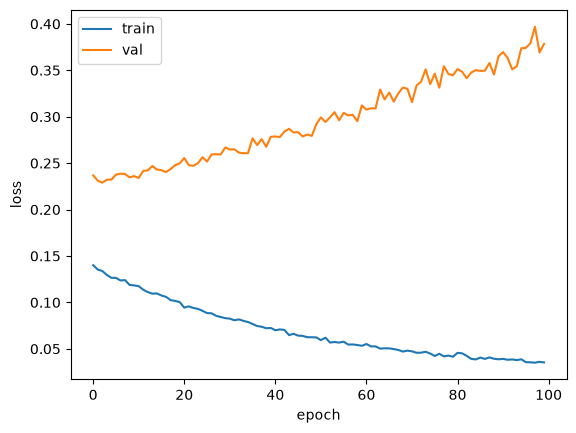

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
model.evaluate(test_scaled, test_target)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9165 - loss: 0.4412


[0.44124507904052734, 0.9164999723434448]